# Mouse pseudotime — CellRank RealTimeKernel → DPT **and** Palantir, from scratch

Reproduces the chain in `fibdec_pseudotime_v2.ipynb` (moscot TemporalProblem → RealTimeKernel → dead-row repair →
RTK-informed diffusion map → DPT) with your exact parameters, and adds **Palantir read off the same RTK graph** —
so DPT and Palantir are two estimators on one time-informed geometry, directly comparable. A plain-kNN Palantir
is kept as the control for "what does the RTK buy".

**Input:** `data/deliverables/2026_09_02_Cevrim_XMens_Only_Fib_Dec_Cells.h5ad` — the object's existing `X_scVI` is reused (`scvi_source = "reuse"`; no retraining). six timepoints → five moscot transitions; the RTK bias is strong here.
**Run on a GPU node** — moscot solves on JAX; `--gres=gpu:1 --mem 200G --cpus-per-task 8`, `rsc_uv`.

Steps: load → day mapping → moscot → RTK (+repair) → RTK diffusion map → **you choose the root** (§5) → DPT + Palantir
on the RTK graph (+ Palantir on plain kNN) → quantile normalisation → gates → violins (fill = median) → spatial.

Conventions carried over: Palantir with `use_early_cell_as_start=True` (palantir 1.4.5 re-picks its own start
otherwise); DC sign measured not assumed; wrong orientation **REFUSED, never flipped**; nothing writes to the object.
The RTK step needs the object's expression matrix (moscot's marginal scoring), so unlike the "loaded" notebooks this
one reads the full h5ad.

In [1]:
import pathlib, json, warnings, time
import numpy as np, pandas as pd, scanpy as sc, anndata as ad
import matplotlib.pyplot as plt, seaborn as sns
from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable
from scipy.stats import spearmanr
from scipy.sparse import csr_matrix, issparse
warnings.filterwarnings("ignore")

X   = pathlib.Path("/n/lab_storage/eddy_lab/users/nhilgert/xmens_final")
SRC = X/"data/deliverables/2026_09_02_Cevrim_XMens_Only_Fib_Dec_Cells.h5ad"
ISO = X/"results/isodepth/mouse_fibdec_isodepth_2026_09_02.h5ad"
DROP_APOPTOTIC = False   # True = drop the annotated decidual_apoptotic cluster (the published RTK run); False = keep every cell
OUT = X/"results/pseudotime_rtk/mouse"/("" if DROP_APOPTOTIC else "with_apoptotic"); OUT.mkdir(parents=True, exist_ok=True)

# ---- parameters, verbatim from fibdec_pseudotime_v2.ipynb CONFIG ----
CFG = dict(
    moscot_gene_set="mouse", moscot_epsilon=1e-3, moscot_tau_a=0.95, moscot_tau_b=0.95,
    rtk_self_transitions="all", rtk_conn_weight=0.2, rtk_threshold="auto",
    n_diffmap_comps=15, seed=0, latent="X_scVI",
    palantir_waypoints=1200, knn_control=30,
    timepoint_to_day={"uninduced": 0.0, "1_dpi_early": 1.0, "1_dpi_late": 1.5, "2_dpi": 2.0, "3_dpi": 3.0, "4_dpi_bleeding": 4.0},
)
SUBORDER = ["efib_outer","efib_middle","efib_middle_induced","efib_subluminal","efib_proliferative",
            "decidual_boundary","decidual_proliferative","decidual_mature"]
if not DROP_APOPTOTIC: SUBORDER = SUBORDER + ["decidual_apoptotic"]
TPORDER  = ["uninduced","1_dpi_early","1_dpi_late","2_dpi","3_dpi","4_dpi_bleeding"]
RANK, TPRANK = {s:i for i,s in enumerate(SUBORDER)}, {t:i for i,t in enumerate(TPORDER)}
PAL  = dict(zip(SUBORDER, sns.color_palette("viridis", len(SUBORDER))))
TPAL = dict(zip(TPORDER,  sns.color_palette("rocket_r", len(TPORDER))))

CHECKS = []
def verify(label, got, note=""):
    ok = bool(got); CHECKS.append((label, ok, str(got), note))
    print(("PASS  " if ok else "FAIL  ") + label + f"   [{got}]" + (f"  {note}" if note else "")); return ok
print("source:", SRC.name, "| exists:", SRC.exists())

source: 2026_09_02_Cevrim_XMens_Only_Fib_Dec_Cells.h5ad | exists: True


## 1 — load and map timepoints to numeric day

The float-categorical `day` column is what `RealTimeKernel` orders on.

In [2]:
a = sc.read_h5ad(SRC); n0 = a.n_obs
for c in ("cell_subtype","timepoint","sample"): a.obs[c] = a.obs[c].astype(str)
if DROP_APOPTOTIC:
    a = a[a.obs.cell_subtype != "decidual_apoptotic"].copy()   # the only drop: annotated apoptotic cluster. uninduced and efib_outer KEPT
else:
    print("DROP_APOPTOTIC=False: keeping all cells incl. decidual_apoptotic")
print("loaded", a.shape, "| dropped:", n0 - a.n_obs)
verify("X_scVI present (reused, not retrained)", CFG["latent"] in a.obsm)
verify("counts layer present", "counts" in a.layers)
verify("QC'd coordinates + tissue_section present", {"x_um_qc","y_um_qc","tissue_section"} <= set(a.obs.columns))
if "dpt_pseudotime" in a.obs: a.obs = a.obs.rename(columns={"dpt_pseudotime": "dpt_pseudotime_onobject"})   # keep the old one for comparison in §9

mapping = {tp: d for tp, d in CFG["timepoint_to_day"].items() if tp in set(a.obs.timepoint)}
unmapped = sorted(set(a.obs.timepoint) - set(mapping)); assert not unmapped, f"timepoints with no day: {unmapped}"
a.obs["day"] = a.obs.timepoint.map(mapping).astype(float).astype("category")   # float-categorical: numeric order preserved
n_tp = len(a.obs.day.cat.categories)
print("day categories:", list(a.obs.day.cat.categories), f"-> moscot couples {n_tp-1} consecutive transition(s)")
if n_tp == 2: print("  NOTE: a single transition — the real-time constraint is weak")
display(pd.crosstab(a.obs.cell_subtype, a.obs.timepoint).reindex(index=[s for s in SUBORDER if s in set(a.obs.cell_subtype)], columns=TPORDER))

DROP_APOPTOTIC=False: keeping all cells incl. decidual_apoptotic
loaded (43197, 33698) | dropped: 0
PASS  X_scVI present (reused, not retrained)   [True]
PASS  counts layer present   [True]
PASS  QC'd coordinates + tissue_section present   [True]
day categories: [0.0, 1.0, 1.5, 2.0, 3.0, 4.0] -> moscot couples 5 consecutive transition(s)


timepoint,uninduced,1_dpi_early,1_dpi_late,2_dpi,3_dpi,4_dpi_bleeding
cell_subtype,,,,,,
efib_outer,1007,70,362,153,348,133
efib_middle,4429,44,152,69,46,24
efib_middle_induced,611,902,3734,920,1522,1086
efib_subluminal,2789,291,724,16,45,21
efib_proliferative,434,118,161,12,37,18
decidual_boundary,28,248,1233,434,1573,206
decidual_proliferative,32,1012,3818,1499,5157,2916
decidual_mature,3,1,472,421,1921,1038
decidual_apoptotic,1,2,131,50,24,699


## 2 — moscot TemporalProblem on `X_scVI`

Unbalanced OT between consecutive days (`tau_a = tau_b = 0.95`), marginals from the species proliferation/apoptosis marker score. GPU.

In [3]:
import jax; print("jax backend:", jax.default_backend())
from moscot.problems.time import TemporalProblem
t0 = time.time()
tp = TemporalProblem(a)
tp = tp.score_genes_for_marginals(gene_set_proliferation=CFG["moscot_gene_set"], gene_set_apoptosis=CFG["moscot_gene_set"])
tp = tp.prepare(time_key="day", joint_attr=CFG["latent"])
tp = tp.solve(epsilon=CFG["moscot_epsilon"], tau_a=CFG["moscot_tau_a"], tau_b=CFG["moscot_tau_b"], scale_cost="mean")
print(f"solved {len(tp.problems)} coupling(s) in {time.time()-t0:.0f}s")
for k, pr in tp.problems.items(): print(f"  {k}: converged={pr.solution.converged}  cost={pr.solution.cost:.4g}")
verify("every moscot coupling converged", all(pr.solution.converged for pr in tp.problems.values()))

Jax plugin configuration error: Exception when calling jax_plugins.xla_cuda12.initialize()
Traceback (most recent call last):
  File "/n/lab_storage/eddy_lab/users/nhilgert/.uv/envs/rsc_uv/lib/python3.11/site-packages/jax/_src/xla_bridge.py", line 487, in discover_pjrt_plugins
    plugin_module.initialize()
  File "/n/lab_storage/eddy_lab/users/nhilgert/.uv/envs/rsc_uv/lib/python3.11/site-packages/jax_plugins/xla_cuda12/__init__.py", line 370, in initialize
    _check_cuda_versions(raise_on_first_error = True)
  File "/n/lab_storage/eddy_lab/users/nhilgert/.uv/envs/rsc_uv/lib/python3.11/site-packages/jax_plugins/xla_cuda12/__init__.py", line 274, in _check_cuda_versions
    for d in range(cuda_versions.cuda_device_count())
                   ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
RuntimeError: jaxlib/cuda/versions_helpers.cc:135: operation cuInit(0) failed: CUDA_ERROR_NO_DEVICE


An NVIDIA GPU may be present on this machine, but a CUDA-enabled jaxlib is not installed. Falling back to cpu.


jax backend: cpu


INFO     Solving `5` problems                                                                                      


INFO     Solving problem BirthDeathProblem[stage='prepared', shape=(9334, 2688)].                                  


INFO     Solving problem BirthDeathProblem[stage='prepared', shape=(10673, 6141)].                                 


INFO     Solving problem BirthDeathProblem[stage='prepared', shape=(2688, 10787)].                                 


INFO     Solving problem BirthDeathProblem[stage='prepared', shape=(3574, 10673)].                                 


INFO     Solving problem BirthDeathProblem[stage='prepared', shape=(10787, 3574)].                                 


solved 5 coupling(s) in 16s
  (0.0, 1.0): converged=True  cost=0.03897
  (3.0, 4.0): converged=True  cost=0.03883
  (1.0, 1.5): converged=True  cost=0.03889
  (2.0, 3.0): converged=True  cost=0.03885
  (1.5, 2.0): converged=True  cost=0.03883
PASS  every moscot coupling converged   [True]


True

## 3 — RealTimeKernel, with the dead-row repair

Verbatim from your cell 30: the stitched couplings can leave all-zero rows (cells no coupling reached), which the CellRank setter rejects at rtol 1e-12. Repair = within-day uniform row, exact renormalisation. Mouse hit this with 6 rows; human did not.

In [4]:
import cellrank as cr
rtk = cr.kernels.RealTimeKernel.from_moscot(tp)
try:
    rtk = rtk.compute_transition_matrix(self_transitions=CFG["rtk_self_transitions"], conn_weight=CFG["rtk_conn_weight"], threshold=CFG["rtk_threshold"])
    T = rtk.transition_matrix; n_dead = 0
    print("RealTimeKernel accepted the stitched matrix directly")
except ValueError as e:
    if "row stochastic" not in str(e): raise
    print(f"RealTimeKernel rejected the matrix: {e}\napplying the documented repair ...")
    T = rtk._transition_matrix if getattr(rtk, "_transition_matrix", None) is not None else \
        rtk._restich_couplings(rtk.couplings, self_transitions=CFG["rtk_self_transitions"], conn_weight=CFG["rtk_conn_weight"]).X
    T = csr_matrix(T).tocsr()
    rs = np.asarray(T.sum(axis=1)).ravel(); dead = np.where(~np.isfinite(rs) | (rs == 0))[0]; n_dead = len(dead)
    print(f"  dead rows (zero / non-finite): {n_dead}")
    day_vals = a.obs.day.astype(float).to_numpy()
    if n_dead:
        T_lil = T.tolil()
        for i in dead:
            same = np.where(day_vals == day_vals[i])[0]; T_lil.rows[i] = list(same); T_lil.data[i] = [1.0/len(same)]*len(same)
        T = T_lil.tocsr()
    rs = np.asarray(T.sum(axis=1)).ravel(); T = csr_matrix(T.multiply(1.0/rs[:, None]))
    rtk.transition_matrix = T; T = rtk.transition_matrix; print("  assigned successfully")
rs = np.asarray(T.sum(axis=1)).ravel()
verify("RTK transition matrix is row-stochastic", np.allclose(rs, 1.0, atol=1e-6), note=f"{T.shape}, {n_dead} rows repaired")

# forward-in-time structure check: what fraction of transition mass goes to a LATER day vs same day vs earlier
dv = a.obs.day.astype(float).to_numpy(); Tc = T.tocoo()
later, same, earlier = [float(Tc.data[np.sign(dv[Tc.col]-dv[Tc.row]) == s].sum()/Tc.data.sum()) for s in (1, 0, -1)]
print(f"transition mass: to later day {later:.3f} | same day {same:.3f} | earlier day {earlier:.3f}")
verify("no transition mass flows backward in time", earlier < 1e-9)

  0%|          | 0/5 [00:00<?, ?time pair/s]

/n/lab_storage/eddy_lab/users/nhilgert/.uv/envs/rsc_uv/lib/python3.11/site-packages/scanpy/neighbors/__init__.py:577: UserWarning: You’re trying to run this on 33698 dimensions of `.X`, if you really want this, set `use_rep='X'`.
         Falling back to preprocessing with `sc.pp.pca` and default params.
  x = _choose_representation(self._adata, use_rep=use_rep, n_pcs=n_pcs)


/n/lab_storage/eddy_lab/users/nhilgert/.uv/envs/rsc_uv/lib/python3.11/site-packages/scanpy/neighbors/__init__.py:577: UserWarning: You’re trying to run this on 33698 dimensions of `.X`, if you really want this, set `use_rep='X'`.
         Falling back to preprocessing with `sc.pp.pca` and default params.
  x = _choose_representation(self._adata, use_rep=use_rep, n_pcs=n_pcs)


/n/lab_storage/eddy_lab/users/nhilgert/.uv/envs/rsc_uv/lib/python3.11/site-packages/scanpy/neighbors/__init__.py:577: UserWarning: You’re trying to run this on 33698 dimensions of `.X`, if you really want this, set `use_rep='X'`.
         Falling back to preprocessing with `sc.pp.pca` and default params.
  x = _choose_representation(self._adata, use_rep=use_rep, n_pcs=n_pcs)


/n/lab_storage/eddy_lab/users/nhilgert/.uv/envs/rsc_uv/lib/python3.11/site-packages/scanpy/neighbors/__init__.py:577: UserWarning: You’re trying to run this on 33698 dimensions of `.X`, if you really want this, set `use_rep='X'`.
         Falling back to preprocessing with `sc.pp.pca` and default params.
  x = _choose_representation(self._adata, use_rep=use_rep, n_pcs=n_pcs)


/n/lab_storage/eddy_lab/users/nhilgert/.uv/envs/rsc_uv/lib/python3.11/site-packages/scanpy/neighbors/__init__.py:577: UserWarning: You’re trying to run this on 33698 dimensions of `.X`, if you really want this, set `use_rep='X'`.
         Falling back to preprocessing with `sc.pp.pca` and default params.
  x = _choose_representation(self._adata, use_rep=use_rep, n_pcs=n_pcs)


/n/lab_storage/eddy_lab/users/nhilgert/.uv/envs/rsc_uv/lib/python3.11/site-packages/scanpy/neighbors/__init__.py:577: UserWarning: You’re trying to run this on 33698 dimensions of `.X`, if you really want this, set `use_rep='X'`.
         Falling back to preprocessing with `sc.pp.pca` and default params.
  x = _choose_representation(self._adata, use_rep=use_rep, n_pcs=n_pcs)


RealTimeKernel accepted the stitched matrix directly
PASS  RTK transition matrix is row-stochastic   [True]  (43197, 43197), 0 rows repaired
transition mass: to later day 0.686 | same day 0.314 | earlier day 0.000
PASS  no transition mass flows backward in time   [True]


True

## 4 — RTK-informed diffusion map (your cell 32)

DPT's own transition matrix is replaced by the symmetrised RTK matrix, so the diffusion components — and every distance computed from them — live on the time-informed graph. The same symmetrised matrix feeds Palantir in §6.

eigenvalues: [1.     0.9877 0.9765 0.9752 0.9713 0.9623 0.9605 0.9593]
PASS  diffusion map has the requested components   [True]
spearman(DC_i, subtype rank): {'DC1': -0.888, 'DC2': 0.496, 'DC3': 0.284, 'DC4': -0.373, 'DC5': 0.101}
trajectory axis = DC1; early pole = DC1 max
PASS  a DC carries the subtype ordering   [True]  |rho|=0.888


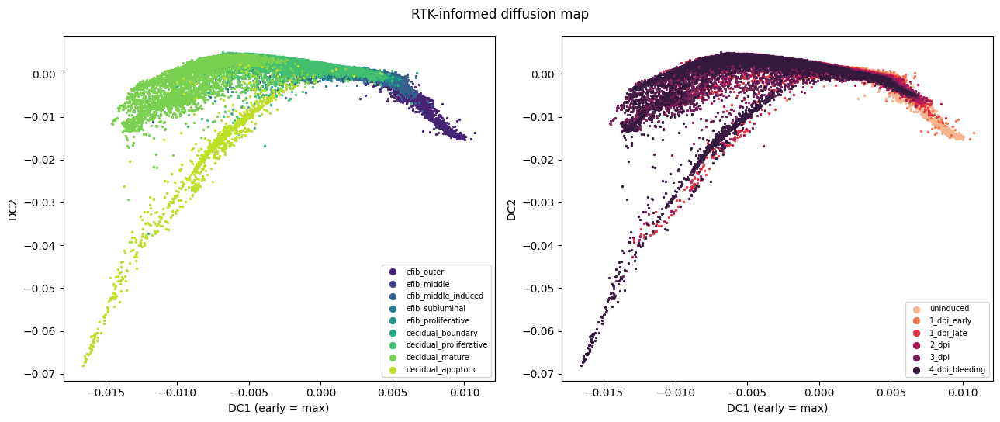

In [5]:
from scanpy.tools._dpt import DPT
def get_symmetric_transition_matrix(transition_matrix):
    """Symmetrize a transition matrix and re-normalize rows. Verbatim from fibdec_pseudotime_v2.ipynb (user helper, not a cellrank function)."""
    sym_mat = (transition_matrix + transition_matrix.T) / 2
    row_sums = sym_mat.sum(axis=1).A1
    sym_mat.data = sym_mat.data / row_sums[sym_mat.nonzero()[0]]
    return sym_mat
sc.pp.neighbors(a, use_rep=CFG["latent"], n_neighbors=CFG["knn_control"], random_state=CFG["seed"])   # plain-kNN control graph
dpt_obj = DPT(adata=a, neighbors_key="neighbors")
T_sym = get_symmetric_transition_matrix(rtk.transition_matrix)
dpt_obj._transitions_sym = T_sym
dpt_obj.compute_eigen(n_comps=CFG["n_diffmap_comps"], random_state=CFG["seed"])
a.obsm["X_diffmap"] = dpt_obj.eigen_basis; a.uns["diffmap_evals"] = dpt_obj.eigen_values
print("eigenvalues:", np.round(a.uns["diffmap_evals"][:8], 4))
DM = a.obsm["X_diffmap"]; O = a.obs
verify("diffusion map has the requested components", DM.shape == (a.n_obs, CFG["n_diffmap_comps"]))

# which DC carries the fib -> dec axis, and which end is early? measured, never assumed
sr = O.cell_subtype.map(RANK).to_numpy(float); ok = np.isfinite(sr)
rhos = {i: float(spearmanr(DM[ok, i], sr[ok]).statistic) for i in range(1, min(6, DM.shape[1]))}
BEST_DC = max(rhos, key=lambda i: abs(rhos[i])); EARLY = "min" if rhos[BEST_DC] > 0 else "max"
print("spearman(DC_i, subtype rank):", {f"DC{i}": round(v, 3) for i, v in rhos.items()})
print(f"trajectory axis = DC{BEST_DC}; early pole = DC{BEST_DC} {EARLY}")
verify("a DC carries the subtype ordering", abs(rhos[BEST_DC]) > 0.3, note=f"|rho|={abs(rhos[BEST_DC]):.3f}")
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
for ax, (pal, col) in zip(axes, ((PAL, "cell_subtype"), (TPAL, "timepoint"))):
    for cat in (SUBORDER if col == "cell_subtype" else TPORDER):
        mm = (O[col] == cat).to_numpy()
        if mm.any(): ax.scatter(DM[mm, BEST_DC], DM[mm, 2 if BEST_DC != 2 else 3], s=2, c=[pal[cat]], label=cat, rasterized=True)
    ax.set_xlabel(f"DC{BEST_DC} (early = {EARLY})"); ax.set_ylabel(f"DC{2 if BEST_DC != 2 else 3}"); ax.legend(fontsize=7, markerscale=4)
fig.suptitle("RTK-informed diffusion map"); fig.tight_layout()

## 5 — **choose the root** (edit this cell)

default root: most extreme uninduced `efib_outer` at the early pole of the RTK diffusion map — first subtype in your order, earliest day. Your Aug-29 run rooted at `efib_proliferative` (which no longer holds with `efib_outer` first). `ROOT_BARCODE` overrides everything. `root_grid()` lists every subtype × timepoint pool with its depth into the early pole.

In [6]:
ROOT_BARCODE = None
ROOT = dict(subtype="efib_outer", timepoint="uninduced", pct=0)   # earliest subtype in the user's order, earliest day

def _resolve(subtype=None, timepoint=None, pct=0):
    m = np.ones(a.n_obs, bool)
    if subtype:   m &= (O.cell_subtype == subtype).to_numpy()
    if timepoint: m &= (O.timepoint == timepoint).to_numpy()
    if not m.any(): raise ValueError(f"filter {dict(subtype=subtype, timepoint=timepoint)} matches 0 cells; timepoints {sorted(set(O.timepoint))}, subtypes {sorted(set(O.cell_subtype))}")
    v = DM[:, BEST_DC].copy(); v[~m] = np.nan
    q = np.nanpercentile(v, pct if EARLY == "min" else 100 - pct)
    idx = int(np.nanargmin(np.abs(v - q)))
    return O.index[idx], idx, int(m.sum())

def root_grid():
    rows = []
    for st in [s for s in SUBORDER if s in set(O.cell_subtype)]:
        for tpn in [t for t in TPORDER if t in set(O.timepoint)]:
            m = ((O.cell_subtype == st) & (O.timepoint == tpn)).to_numpy()
            if m.sum() < 50: continue
            ext = DM[m, BEST_DC].min() if EARLY == "min" else DM[m, BEST_DC].max()
            depth = float((DM[:, BEST_DC] > ext).mean() if EARLY == "min" else (DM[:, BEST_DC] < ext).mean())
            rows.append(dict(subtype=st, timepoint=tpn, n=int(m.sum()), depth_into_early_pole=round(depth, 4)))
    return pd.DataFrame(rows).sort_values("depth_into_early_pole", ascending=False)
print("root options (depth 1.00 = deepest into the early pole):"); display(root_grid().head(24))

if ROOT_BARCODE:
    assert ROOT_BARCODE in O.index; ROOT_BC, ROOT_IDX, npool = ROOT_BARCODE, int(O.index.get_loc(ROOT_BARCODE)), 1
else:
    ROOT_BC, ROOT_IDX, npool = _resolve(**ROOT)
print(f"\nroot: {ROOT_BC}  subtype={O.cell_subtype.iloc[ROOT_IDX]}  timepoint={O.timepoint.iloc[ROOT_IDX]}  sample={O['sample'].iloc[ROOT_IDX]}  (pool {npool})")
verify("root subtype is the first in SUBORDER", RANK[O.cell_subtype.iloc[ROOT_IDX]] == 0,
       note="a later-subtype root pins that subtype to 0 and drags earlier ones behind it")
verify("root is at the earliest day", float(O.day.iloc[ROOT_IDX]) == float(O.day.astype(float).min()))

root options (depth 1.00 = deepest into the early pole):


,subtype,timepoint,n,depth_into_early_pole
1,efib_outer,1_dpi_early,70,1.0000
0,efib_outer,uninduced,1007,0.9999
2,efib_outer,1_dpi_late,362,0.9923
3,efib_outer,2_dpi,153,0.9899
10,efib_middle_induced,1_dpi_early,902,0.9856
4,efib_outer,3_dpi,348,0.9843
9,efib_middle_induced,uninduced,611,0.9819
5,efib_outer,4_dpi_bleeding,133,0.9803
11,efib_middle_induced,1_dpi_late,3734,0.9781
12,efib_middle_induced,2_dpi,920,0.9780



root: ATCCATTAGTTGTCAC-1-uninduced_mck8a  subtype=efib_outer  timepoint=uninduced  sample=uninduced_mck8a  (pool 1007)
PASS  root subtype is the first in SUBORDER   [True]  a later-subtype root pins that subtype to 0 and drags earlier ones behind it
PASS  root is at the earliest day   [True]


True

## 6 — DPT and Palantir from that root, on the RTK graph; Palantir on plain kNN as control

`palantir.utils.run_diffusion_maps` accepts an adjacency matrix directly, so the symmetrised RTK matrix goes in as-is (`alpha=0`: the RTK is already a normalised operator). The control is Palantir's own kNN kernel on `X_scVI`.

In [7]:
import palantir
a.uns["iroot"] = ROOT_IDX
sc.tl.dpt(a, n_dcs=CFG["n_diffmap_comps"])                      # uses a.obsm["X_diffmap"] = the RTK-informed one
res = O[["cell_subtype","timepoint","sample","x_um_qc","y_um_qc","tissue_section"]].copy()
res["dpt_rtk"] = a.obs["dpt_pseudotime"].to_numpy(float)

def run_pal(dm_input, label):
    """dm_input: scipy sparse (N x N) -> used as a precomputed KERNEL (Palantir row-normalizes it; T_sym is
    already row-stochastic so this is idempotent and the operator is identical to the DPT path above).
               dense DataFrame (N x d)  -> Palantir builds its own adaptive kNN kernel (the plain-kNN control)."""
    t0 = time.time()
    if issparse(dm_input):
        dm = palantir.utils.diffusion_maps_from_kernel(dm_input, n_components=CFG["n_diffmap_comps"], seed=CFG["seed"])
        for k in ("EigenVectors",):                     # kernel path returns positional index; restore barcodes
            dm[k].index = O.index
    else:
        dm = palantir.utils.run_diffusion_maps(dm_input, n_components=CFG["n_diffmap_comps"], knn=CFG["knn_control"], seed=CFG["seed"])
    ms = palantir.utils.determine_multiscale_space(dm)
    pr = palantir.core.run_palantir(ms, early_cell=ROOT_BC, use_early_cell_as_start=True,
                                    num_waypoints=CFG["palantir_waypoints"], seed=CFG["seed"])
    print(f"{label}: {time.time()-t0:.0f}s | multiscale dims {ms.shape[1]}")
    return pr.pseudotime.reindex(O.index).to_numpy(float)

A_rtk = csr_matrix(T_sym)                          # scipy sparse, NOT a pandas sparse DataFrame:
                                                   # issparse() must be True or Palantir treats N x N as features -> OOM
res["palantir_rtk"] = run_pal(A_rtk, "Palantir on RTK graph")
res["palantir_knn"] = run_pal(pd.DataFrame(a.obsm[CFG["latent"]], index=O.index), "Palantir on plain kNN (control)")
if "dpt_pseudotime_onobject" in O: res["dpt_onobject"] = pd.to_numeric(O.dpt_pseudotime_onobject, errors="coerce").to_numpy(float)

METHODS = ["dpt_rtk", "palantir_rtk", "palantir_knn"]
for m in METHODS:
    verify(f"{m}: finite everywhere", np.isfinite(res[m]).all(), note=f"{int((~np.isfinite(res[m])).sum())} non-finite")
    verify(f"{m}: is 0 at the root", float(res[m].iloc[ROOT_IDX]) == 0.0 or abs(float(res[m].iloc[ROOT_IDX])) < 1e-9, note=f"{res[m].iloc[ROOT_IDX]:.4g}")
print("\nmethod agreement (spearman):")
display(res[METHODS + ([c for c in ("dpt_onobject",) if c in res])].corr(method="spearman").round(3))

Sampling and flocking waypoints...
Time for determining waypoints: 0.0006786346435546875 minutes
Determining pseudotime...
Shortest path distances using 30-nearest neighbor graph...


Time for shortest paths: 0.374473508199056 minutes
Iteratively refining the pseudotime...


Correlation at iteration 1: 1.0000
Entropy and branch probabilities...
Markov chain construction...
Identification of terminal states...
Computing fundamental matrix and absorption probabilities...
Project results to all cells...


Palantir on RTK graph: 29s | multiscale dims 2


Sampling and flocking waypoints...
Time for determining waypoints: 0.0003099799156188965 minutes
Determining pseudotime...
Shortest path distances using 30-nearest neighbor graph...


Time for shortest paths: 0.3759059548377991 minutes
Iteratively refining the pseudotime...


Correlation at iteration 1: 0.9996


Correlation at iteration 2: 1.0000
Entropy and branch probabilities...
Markov chain construction...
Identification of terminal states...
Computing fundamental matrix and absorption probabilities...
Project results to all cells...


Palantir on plain kNN (control): 34s | multiscale dims 4
PASS  dpt_rtk: finite everywhere   [True]  0 non-finite
PASS  dpt_rtk: is 0 at the root   [True]  0
PASS  palantir_rtk: finite everywhere   [True]  0 non-finite
FAIL  palantir_rtk: is 0 at the root   [False]  2.574e-05
PASS  palantir_knn: finite everywhere   [True]  0 non-finite
PASS  palantir_knn: is 0 at the root   [True]  0

method agreement (spearman):


,dpt_rtk,palantir_rtk,palantir_knn,dpt_onobject
dpt_rtk,1.000,0.978,0.912,0.987
palantir_rtk,0.978,1.000,0.923,0.969
palantir_knn,0.912,0.923,1.000,0.893
dpt_onobject,0.987,0.969,0.893,1.000


## 7 — quantile normalisation

`_q` global percentile, `_qsec` within section; ordering preservation asserted.

In [8]:
for m in METHODS:
    res[f"{m}_q"]    = res[m].rank(pct=True)
    res[f"{m}_qsec"] = res.groupby("tissue_section", observed=True)[m].rank(pct=True)
    verify(f"{m}: quantile transform preserves ordering", float(spearmanr(res[m], res[f"{m}_q"]).statistic) == 1.0)

FAIL  dpt_rtk: quantile transform preserves ordering   [False]
PASS  palantir_rtk: quantile transform preserves ordering   [True]
PASS  palantir_knn: quantile transform preserves ordering   [True]


## 8 — orientation gates (REFUSED, never flipped)

Subtype-rank ρ overall and within fibroblasts; day ρ within the decidual compartment (pooled day ρ is composition-confounded). The root-pinning check catches a root whose own subtype is dragged to zero ahead of earlier ones.

In [9]:
def gates(pt):
    sr = res.cell_subtype.map(RANK).to_numpy(float); tr = res.timepoint.map(TPRANK).to_numpy(float); ok = np.isfinite(pt)
    dec = ok & res.cell_subtype.str.startswith("decidual").to_numpy(); fib = ok & ~res.cell_subtype.str.startswith("decidual").to_numpy()
    rho = lambda m, y: round(float(spearmanr(pt[m], y[m]).statistic), 4) if m.sum() > 50 else None
    med = pd.Series(pt, index=res.index).groupby(res.cell_subtype).median()
    root_sub = O.cell_subtype.iloc[ROOT_IDX]
    pinned = [s for s in SUBORDER if s in med and RANK[s] < RANK[root_sub] and med[s] > med[root_sub]]
    d = dict(rho_subtype=rho(ok, sr), rho_subtype_fibroblasts=rho(fib, sr), rho_day_all=rho(ok, tr),
             rho_day_decidual_only=rho(dec, tr), rho_day_fibroblasts_only=rho(fib, tr), subtypes_pinned_behind_root=pinned)
    bad = (d["rho_subtype"] or 0) <= 0 or (d["rho_day_decidual_only"] or 0) <= 0
    d["verdict"] = "REFUSED — orientation gate failed; NOT flipped, choose another root" if bad else "OK"
    return d
GATES = {m: gates(res[m].to_numpy()) for m in METHODS}; display(pd.DataFrame(GATES).T)
for m, g in GATES.items():
    verify(f"{m}: orientation", g["verdict"] == "OK", note=g["verdict"])
    verify(f"{m}: no subtype pinned behind the root", not g["subtypes_pinned_behind_root"], note=str(g["subtypes_pinned_behind_root"]))

,rho_subtype,rho_subtype_fibroblasts,rho_day_all,rho_day_decidual_only,rho_day_fibroblasts_only,subtypes_pinned_behind_root,verdict
dpt_rtk,0.8806,0.5299,0.6264,0.5009,0.1283,[],OK
palantir_rtk,0.8906,0.526,0.5702,0.481,-0.0907,[],OK
palantir_knn,0.8531,0.5338,0.4082,0.425,-0.4262,[],OK


PASS  dpt_rtk: orientation   [True]  OK
PASS  dpt_rtk: no subtype pinned behind the root   [True]  []
PASS  palantir_rtk: orientation   [True]  OK
PASS  palantir_rtk: no subtype pinned behind the root   [True]  []
PASS  palantir_knn: orientation   [True]  OK
PASS  palantir_knn: no subtype pinned behind the root   [True]  []


## 9 — violins: raw vs quantile, fill = category median

One figure per method (rows) × grouping. Fill colour = that category's median on the column's own scale, matching the spatial panels.

,dpt_rtk,dpt_rtk_q,palantir_rtk,palantir_rtk_q,palantir_knn,palantir_knn_q
cell_subtype,,,,,,
efib_outer,0.2824,0.0251,0.1059,0.0242,0.1666,0.0240
efib_middle,0.3514,0.1973,0.1737,0.2205,0.4062,0.2920
efib_middle_induced,0.3536,0.2393,0.1721,0.2083,0.3794,0.1564
efib_subluminal,0.3625,0.3996,0.1986,0.3699,0.4612,0.5830
efib_proliferative,0.3615,0.3824,0.2113,0.4264,0.4425,0.4596
decidual_boundary,0.3783,0.5549,0.2717,0.5586,0.4420,0.4562
decidual_proliferative,0.3991,0.7129,0.3397,0.7155,0.4778,0.6992
decidual_mature,0.4628,0.9315,0.4888,0.9413,0.5844,0.9310
decidual_apoptotic,0.5332,0.9817,0.4989,0.9487,0.9127,0.9895


,dpt_rtk,dpt_rtk_q,palantir_rtk,palantir_rtk_q,palantir_knn,palantir_knn_q
timepoint,,,,,,
uninduced,0.3530,0.2277,0.1785,0.2648,0.4122,0.3311
1_dpi_early,0.3616,0.3841,0.2096,0.4177,0.4321,0.4221
1_dpi_late,0.3664,0.4474,0.2301,0.4743,0.4330,0.4258
2_dpi,0.3814,0.5803,0.2838,0.5845,0.4524,0.5317
3_dpi,0.4014,0.7267,0.3442,0.7247,0.4738,0.6781
4_dpi_bleeding,0.4137,0.7910,0.3803,0.7904,0.5045,0.8008


median quantile pseudotime by timepoint x compartment (pooled violins are composition-driven):


dpt_rtk_q            palantir_knn_q            palantir_rtk_q  \
compartment     decidual fibroblast       decidual fibroblast       decidual   
timepoint                                                                      
uninduced          0.295      0.227          0.414      0.330          0.400   
1_dpi_early        0.478      0.220          0.504      0.225          0.500   
1_dpi_late         0.612      0.186          0.609      0.151          0.622   
2_dpi              0.687      0.210          0.680      0.131          0.693   
3_dpi              0.773      0.344          0.751      0.161          0.772   
4_dpi_bleeding     0.845      0.381          0.848      0.136          0.843   

                           
compartment    fibroblast  
timepoint                  
uninduced           0.263  
1_dpi_early         0.270  
1_dpi_late          0.194  
2_dpi               0.207  
3_dpi               0.228  
4_dpi_bleeding      0.205

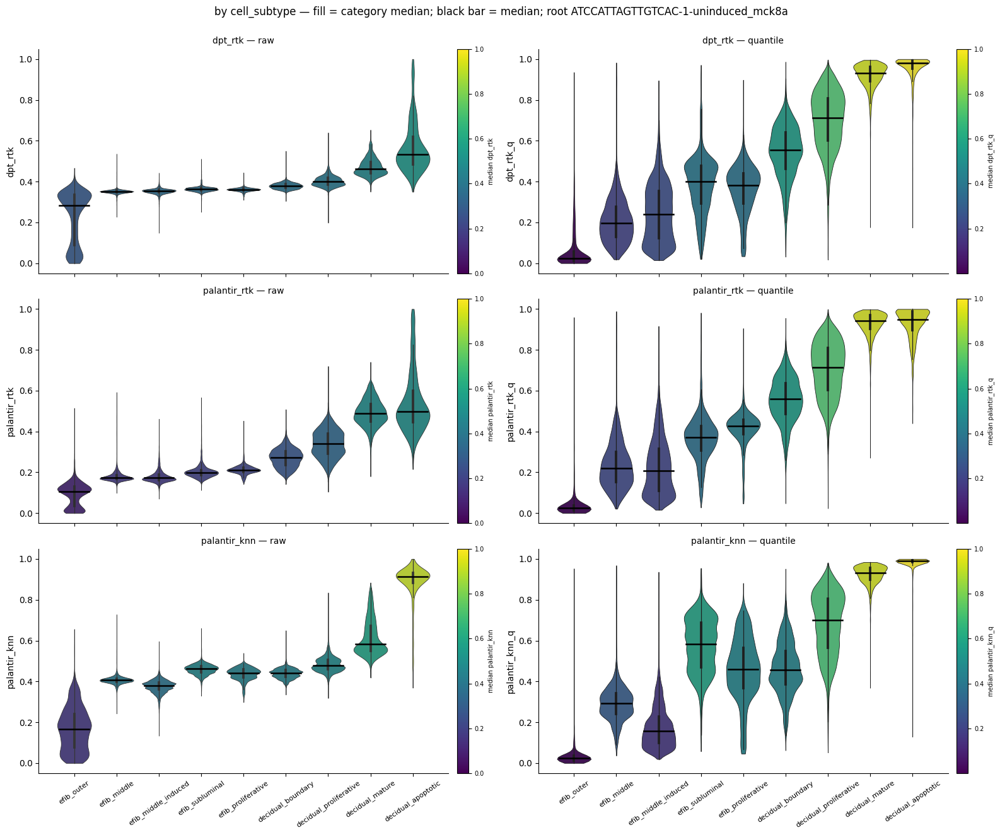

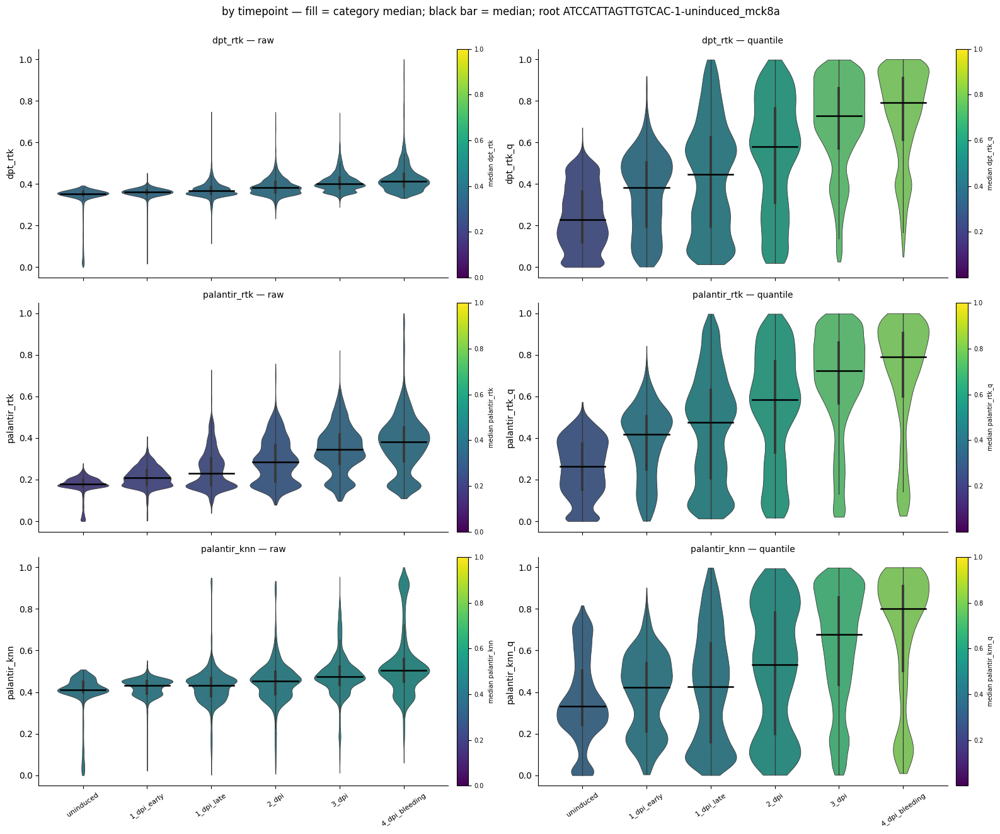

In [10]:
def violins(by, order=None, cmap="viridis", methods=METHODS):
    order = order or [s for s in (SUBORDER if by == "cell_subtype" else TPORDER) if s in set(res[by])]
    fig, axes = plt.subplots(len(methods), 2, figsize=(16, 4.4*len(methods)), sharex=True, squeeze=False)
    meds = {}
    for i, m in enumerate(methods):
        for j, col in enumerate((m, f"{m}_q")):
            ax = axes[i][j]
            med = res.groupby(by, observed=True)[col].median().reindex(order); meds[col] = med
            norm = Normalize(vmin=float(res[col].min()), vmax=float(res[col].max()))
            colours = {c_: plt.get_cmap(cmap)(norm(med[c_])) for c_ in order if pd.notna(med[c_])}
            sns.violinplot(data=res, x=by, y=col, order=order, hue=by, hue_order=order, palette=colours, legend=False, cut=0, linewidth=.6, ax=ax)
            for k, c_ in enumerate(order):
                if pd.notna(med.get(c_)): ax.plot([k-.35, k+.35], [med[c_]]*2, c="k", lw=1.8, zorder=5)
            ax.set_title(f"{m} — {'quantile' if col.endswith('_q') else 'raw'}", fontsize=10); ax.set_xlabel(""); ax.tick_params(axis="x", rotation=35, labelsize=8)
            cb = fig.colorbar(ScalarMappable(norm=norm, cmap=cmap), ax=ax, fraction=.046, pad=.02); cb.set_label(f"median {col}", fontsize=7); cb.ax.tick_params(labelsize=7)
    fig.suptitle(f"by {by} — fill = category median; black bar = median; root {ROOT_BC}", y=1.0); fig.tight_layout()
    return fig, pd.DataFrame(meds).round(4)
fig, MED_SUB = violins("cell_subtype"); display(MED_SUB)
fig, MED_TP  = violins("timepoint");    display(MED_TP)
res["compartment"] = np.where(res.cell_subtype.str.contains("decidual"), "decidual", "fibroblast")
print("median quantile pseudotime by timepoint x compartment (pooled violins are composition-driven):")
display(res.pivot_table(index="timepoint", columns="compartment", values=[f"{m}_q" for m in METHODS], aggfunc="median", observed=True).reindex(TPORDER).round(3))

## 10 — spatial: one row per section; columns = methods, raw and quantile

Raw and global quantile share a colour scale across sections; sections never pooled within a timepoint.

23,647 cells with a coordinate | 11 sections


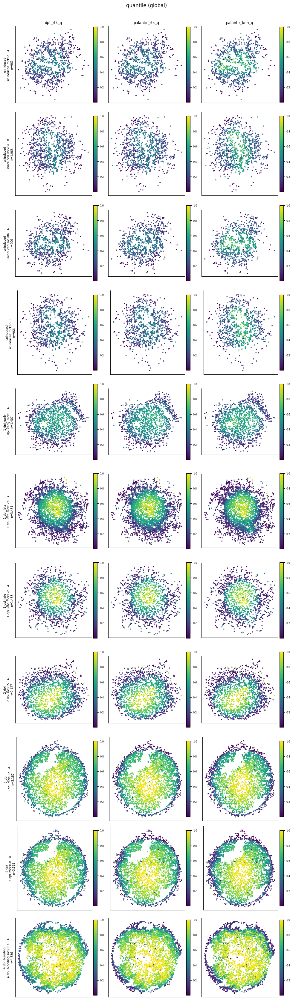

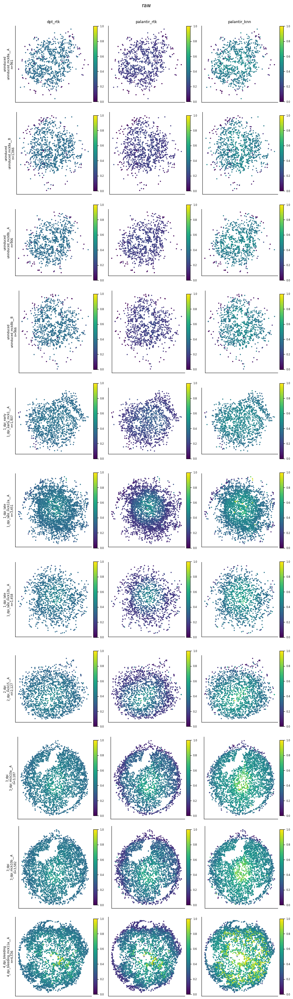

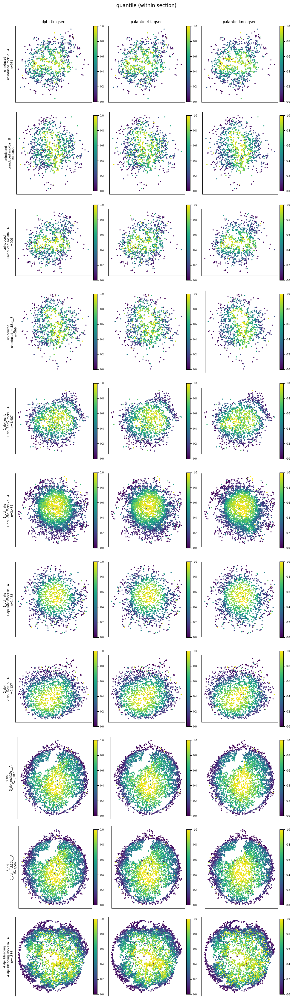

In [11]:
SP = res[np.isfinite(res.x_um_qc) & res.tissue_section.notna() & (res.tissue_section.astype(str) != "nan")].copy()
SEC2TP = SP.groupby("tissue_section", observed=True).timepoint.first().to_dict()
secs = sorted(SP.tissue_section.unique(), key=lambda s: (TPRANK.get(SEC2TP[s], 99), s))
print(f"{len(SP):,} cells with a coordinate | {len(secs)} sections")

def spatial(methods=METHODS, suffix="_q", per=3.3, s=3.0):
    cols = [f"{m}{suffix}" for m in methods]
    fig, axes = plt.subplots(len(secs), len(cols), figsize=(per*len(cols), per*len(secs)*.92), squeeze=False)
    for i, sec in enumerate(secs):
        g = SP[SP.tissue_section == sec]
        for j, col in enumerate(cols):
            ax = axes[i][j]; vmin, vmax = (0, 1) if suffix == "_qsec" else (float(SP[col].min()), float(SP[col].max()))
            sm = ax.scatter(g.x_um_qc, g.y_um_qc, c=g[col], s=s, cmap="viridis", vmin=vmin, vmax=vmax, rasterized=True)
            ax.set_aspect("equal"); ax.set_xticks([]); ax.set_yticks([])
            if i == 0: ax.set_title(col, fontsize=9)
            if j == 0: ax.set_ylabel(f"{SEC2TP[sec]}\n{sec}\nn={len(g):,}", fontsize=7)
            plt.colorbar(sm, ax=ax, fraction=.046, pad=.02).ax.tick_params(labelsize=6)
    fig.suptitle({"": "raw", "_q": "quantile (global)", "_qsec": "quantile (within section)"}[suffix], y=1.0); fig.tight_layout(); return fig
_ = spatial(suffix="_q"); _ = spatial(suffix=""); _ = spatial(suffix="_qsec")

### pseudotime vs isodepth per section (if the isodepth object is present)

In [12]:
if ISO.exists():
    import h5py
    try:    from anndata.io import read_elem
    except ImportError: from anndata.experimental import read_elem
    with h5py.File(ISO, "r") as f:
        iso = pd.Series(np.asarray(read_elem(f["obs/isodepth_consensus"])).ravel(), index=np.asarray(read_elem(f["obs/_index"])).ravel()).astype(float)
    SP["isodepth"] = iso.reindex(SP.index).to_numpy()
    rows = []
    for sec in secs:
        g = SP[(SP.tissue_section == sec) & np.isfinite(SP.isodepth)]
        if len(g) < 50: continue
        rows.append(dict(section=sec, timepoint=SEC2TP[sec], n=len(g), **{m: round(float(spearmanr(g[m], g.isodepth).statistic), 3) for m in METHODS}))
    display(pd.DataFrame(rows).set_index("section"))
else:
    print("isodepth object not found at", ISO)

,timepoint,n,dpt_rtk,palantir_rtk,palantir_knn
section,,,,,
uninduced_mck8a__A,uninduced,961,0.749,0.736,0.899
uninduced_mck8a__B,uninduced,1066,0.743,0.736,0.895
uninduced_mck8b__A,uninduced,906,0.738,0.726,0.882
uninduced_mck8b__B,uninduced,966,0.771,0.765,0.905
1_dpi_early_mck1__A,1_dpi_early,1407,0.819,0.837,0.863
1_dpi_late_mck12a__A,1_dpi_late,3451,0.677,0.674,0.724
1_dpi_late_mck12b__A,1_dpi_late,1458,0.688,0.686,0.733
2_dpi_mck15__A,2_dpi,2127,0.787,0.795,0.817
3_dpi_mck10a__A,3_dpi,3187,0.858,0.865,0.879


## 11 — save

Per-cell table with all three pseudotimes (+ the one that was on the object) and a report; the h5ad is not modified.

In [13]:
tag = (ROOT_BARCODE or f"{ROOT.get('timepoint','any')}_{ROOT.get('subtype','any')}").replace("/", "_")
res.to_csv(OUT/f"pseudotime_rtk_{tag}.csv")
json.dump(dict(species="mouse", source=str(SRC), n_cells=int(a.n_obs), root=ROOT_BC, root_spec=(ROOT_BARCODE or ROOT), best_dc=int(BEST_DC), early=EARLY,
               config=CFG, n_transitions=int(n_tp-1), rtk_dead_rows_repaired=int(n_dead), transition_mass=dict(later=later, same=same, earlier=earlier),
               gates=GATES, methods=METHODS, versions=dict(cellrank=cr.__version__, palantir=palantir.__version__, scanpy=sc.__version__),
               use_early_cell_as_start=True, checks=[dict(label=l, ok=o, got=g) for l, o, g, _ in CHECKS]),
          open(OUT/f"pseudotime_rtk_{tag}_report.json", "w"), indent=1, default=str)
bad = [l for l, o, _, _ in CHECKS if not o]
print("wrote", OUT/f"pseudotime_rtk_{tag}.csv"); print(f"{len(CHECKS)} checks | {len(bad)} FAILED" + (": " + "; ".join(bad) if bad else " — all passed"))

wrote /n/lab_storage/eddy_lab/users/nhilgert/xmens_final/results/pseudotime_rtk/mouse/with_apoptotic/pseudotime_rtk_uninduced_efib_outer.csv
25 checks | 2 FAILED: palantir_rtk: is 0 at the root; dpt_rtk: quantile transform preserves ordering


In [14]:
# ---- export the RTK diffusion map (eigenvectors + eigenvalues) alongside the pseudotime ----
dm = pd.DataFrame(a.obsm["X_diffmap"], index=a.obs_names,
                  columns=[f"DC{i}" for i in range(a.obsm["X_diffmap"].shape[1])])
dm.to_csv(OUT/f"diffmap_rtk_{tag}.csv")
json.dump(dict(species="mouse", drop_apoptotic=DROP_APOPTOTIC, n_cells=int(a.n_obs), n_comps=int(dm.shape[1]),
               best_dc=int(BEST_DC), evals=[float(v) for v in a.uns["diffmap_evals"]],
               kernel="symmetrized RTK transition matrix (cell 9)", source=str(SRC)),
          open(OUT/f"diffmap_rtk_{tag}_evals.json", "w"), indent=1)
print("wrote", OUT/f"diffmap_rtk_{tag}.csv", dm.shape)


wrote /n/lab_storage/eddy_lab/users/nhilgert/xmens_final/results/pseudotime_rtk/mouse/with_apoptotic/diffmap_rtk_uninduced_efib_outer.csv (43197, 15)
